# Phase 6c: Explainability (SHAP) and Ethical Bias Check

**Project:** FMCG Global Demand Planning Capstone
**Inputs:** `models/best_model.txt` and `models/feature_cols.json` (Phase 5), `data/fmcg_features.parquet` (Phase 4), `data/test_predictions.csv` (Phase 5), `data/fmcg_clean.csv`
**Outputs:** tables and figures in `reports/`

The brief's Step 6 asks two questions:
1. **Explainability:** which drivers does the model rely on, historical lags (momentum) or active promotions? Transparency is required for S&OP buy-in.
2. **Ethics (bias detection):** does the model systematically under-allocate stock to **Traditional Trade** in favour of Modern Trade and E-commerce, which would marginalise local community retailers?

## Part A: SHAP explainability
**SHAP** assigns every feature a contribution to each individual forecast, and the contributions add up to the forecast. Averaging their absolute size over many forecasts ranks the drivers; plotting them against feature values shows *how* each driver acts.

## Part B: Traditional Trade bias check
**Channel mapping (an assumption to state in the report).** The dataset has four channels, not the four in the brief:

| Brief | This dataset |
|---|---|
| Traditional Trade (kiosks, dukas) | **Convenience** (closest proxy: small-format stores) |
| Modern Trade | Hypermarket, Supermarket |
| E-commerce | E-commerce |
| Wholesale | not present |

Convenience is only about 2.6% of sales (45 series), and it is a European convenience format, not an informal kiosk, so conclusions are indicative and have limited statistical power.

## 1. Setup

In [1]:
# Run once; harmless if already installed.
%pip install lightgbm scipy shap

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy import stats as st

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 5)
os.makedirs("../reports/figures", exist_ok=True)
SEED = 42

# LightGBM computes exact TreeSHAP values itself (predict(..., pred_contrib=True)), so the `shap`
# package is only needed for the beeswarm plot. If it is missing, that one plot is skipped.
try:
    import shap
    HAVE_SHAP = True
except Exception:
    HAVE_SHAP = False
    print("shap package not available: the beeswarm plot will be skipped; all other results are unaffected.")

def savefig(name):
    plt.savefig(f"../reports/figures/{name}.png", dpi=150, bbox_inches="tight")

# Part A: SHAP explainability

## 2. Load the saved model and a sample of test rows
SHAP on all ~185,000 test rows would be slow, so we explain a random sample of 20,000 rows from the test period (Jul-Dec 2023).

**Reading SHAP values for this model.** If the best LightGBM used the **Poisson** objective (as chosen in Phase 5 if so), the model works on the **log scale**: contributions add up to the log of the forecast, so `exp(contribution)` is a **multiplier** on expected units (for example 1.4 means "this feature raises the forecast by 40%"). With a squared-error objective, contributions are plain unit amounts. The code below detects which case applies.

In [3]:
meta = json.load(open("../models/feature_cols.json"))
feature_cols, target = meta["features"], meta["target"]
assert meta["best_model"] == "LightGBM", f"This notebook explains the LightGBM model; best model was {meta['best_model']}"

booster = lgb.Booster(model_file="../models/best_model.txt")

tune = pd.read_csv("../reports/tuning_results.csv")
objective = tune[tune["family"] == "LightGBM"].iloc[0]["objective"]
LOG_SCALE = objective == "poisson"
print("Objective:", objective, "| contributions on", "log scale (use exp for multipliers)" if LOG_SCALE else "unit scale")

try:
    feats = pd.read_parquet("../data/fmcg_features.parquet")
except Exception:
    feats = pd.read_csv("../data/fmcg_features.csv", parse_dates=["date"])

test = feats[feats["date"] >= "2023-07-01"].reset_index(drop=True)
sample = test.sample(20_000, random_state=SEED).reset_index(drop=True)
X = sample[feature_cols]
print("Test rows:", f"{len(test):,}", "| explained sample:", len(X), "| features:", len(feature_cols))

Objective: poisson | contributions on log scale (use exp for multipliers)
Test rows: 184,736 | explained sample: 20000 | features: 31


## 3. Compute SHAP values and check they add up

In [4]:
# LightGBM returns one contribution per feature plus the base value in the last column.
contrib = booster.predict(X, pred_contrib=True)
sv = contrib[:, :-1]
base_value = contrib[0, -1]

# Additivity check: base value + sum of contributions must equal the model's raw output.
raw_out = booster.predict(X, raw_score=True)
max_gap = np.abs(contrib.sum(axis=1) - raw_out).max()
print(f"Max |base + sum(SHAP) - raw model output|: {max_gap:.6f}")
print("SHAP matrix:", sv.shape)

Max |base + sum(SHAP) - raw model output|: 0.000000
SHAP matrix: (20000, 31)


## 4. Global importance: lags or promotions?
The brief's question: *does the model rely more on historical lags (momentum) or active promotions?* We group features by meaning and add up their share of total importance (mean absolute SHAP value).

In [5]:
groups = {
    "Recent demand history (lags, rolling mean/std, past promos)":
        ["lag_1", "lag_7", "lag_14", "lag_30", "roll_mean_7", "roll_std_7", "roll_mean_30", "roll_std_30", "promo_last7"],
    "Active promotion today (flag, discount depth)": ["promo_flag", "discount_pct"],
    "Stock-out history": ["stockout_lag1", "stockout_last7"],
    "Calendar (weekday, weekend, month, holiday)": ["is_holiday", "is_weekend", "weekday", "month", "day", "weekofyear"],
    "Price and weather": ["list_price", "temperature", "rain_mm"],
    "Series identity (country, channel, category, SKU, store, segment)":
        ["country_code", "channel_code", "category_code", "subcategory_code", "brand_code",
         "store_id_code", "sku_id_code", "abc_code", "xyz_rel_code"],
}
assigned = {f for fs in groups.values() for f in fs}
leftover = [f for f in feature_cols if f not in assigned]
if leftover:
    groups["Other"] = leftover
    print("Features not in a named group:", leftover)

mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=feature_cols)
gain = pd.Series(booster.feature_importance(importance_type="gain"), index=feature_cols)

imp = pd.DataFrame({"mean_|SHAP|": mean_abs, "SHAP_share_%": mean_abs / mean_abs.sum() * 100,
                    "gain_share_%": gain / gain.sum() * 100}).sort_values("SHAP_share_%", ascending=False)
print("Top 12 features (SHAP share vs LightGBM gain share, %):")
print(imp.head(12).round(2).to_string())

grp = pd.Series({g: imp.loc[[f for f in fs if f in imp.index], "SHAP_share_%"].sum() for g, fs in groups.items()})
grp = grp.sort_values(ascending=False)
print("\nShare of total importance by feature group (%):")
print(grp.round(1).to_string())
grp.to_csv("../reports/shap_group_importance.csv", header=["share_%"])
imp.to_csv("../reports/shap_feature_importance.csv")

Top 12 features (SHAP share vs LightGBM gain share, %):
              mean_|SHAP|  SHAP_share_%  gain_share_%
roll_mean_30        0.440        49.710        75.230
roll_mean_7         0.090        10.350         7.690
promo_flag          0.060         7.030         6.880
is_weekend          0.060         6.400         1.380
promo_last7         0.040         4.570         1.040
discount_pct        0.020         2.540         1.650
abc_code            0.020         2.520         0.050
list_price          0.020         2.220         0.210
weekday             0.020         1.930         0.430
channel_code        0.020         1.900         0.130
roll_std_30         0.020         1.810         2.090
month               0.010         1.470         0.300

Share of total importance by feature group (%):
Recent demand history (lags, rolling mean/std, past promos)         68.000
Calendar (weekday, weekend, month, holiday)                         10.600
Active promotion today (flag, discount dept

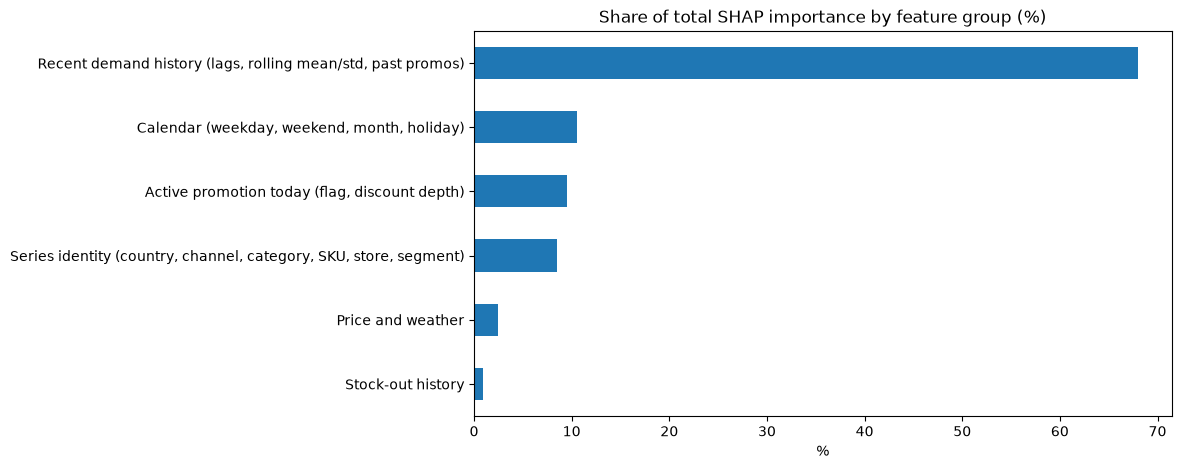

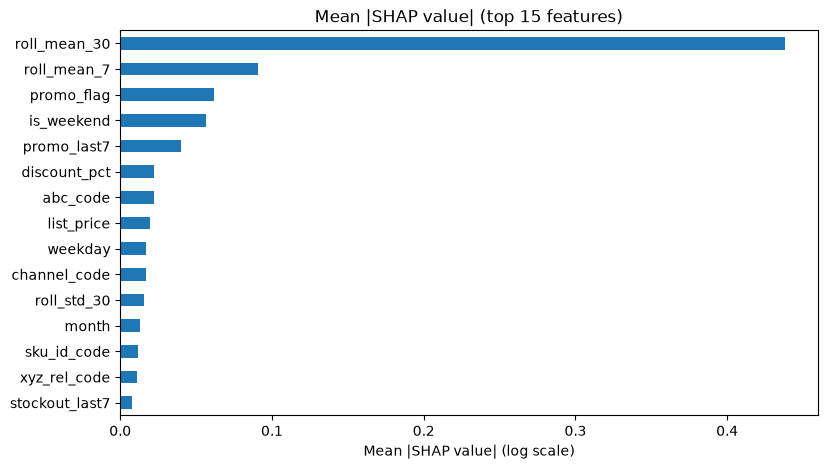

In [6]:
grp.sort_values().plot(kind="barh", title="Share of total SHAP importance by feature group (%)")
plt.xlabel("%")
savefig("shap_groups")
plt.show()

imp["mean_|SHAP|"].head(15).iloc[::-1].plot(kind="barh", title="Mean |SHAP value| (top 15 features)")
plt.xlabel("Mean |SHAP value|" + (" (log scale)" if LOG_SCALE else " (units)"))
savefig("shap_bar")
plt.show()

## 5. How each driver acts (beeswarm and dependence plots)
**Beeswarm:** each dot is one forecast. Horizontal position = how much that feature pushed the forecast up (right) or down (left); colour = the feature's value (red high, blue low).

**Dependence plots:** the contribution of one feature against its own value. For the discount, this shows the shape of the promotion effect.

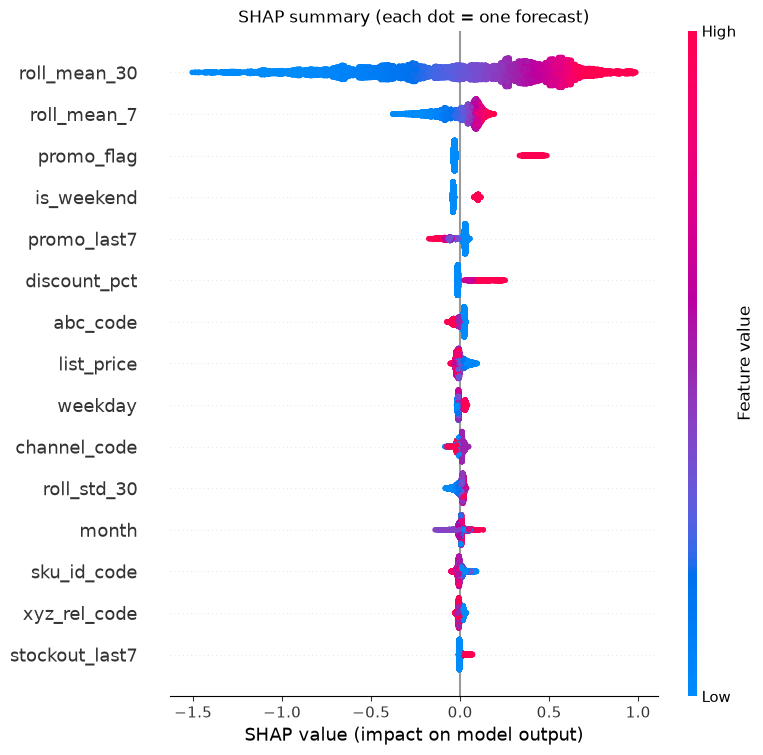

In [7]:
if HAVE_SHAP:
    shap.summary_plot(sv, X, max_display=15, show=False)
    plt.title("SHAP summary (each dot = one forecast)")
    savefig("shap_beeswarm")
    plt.show()
else:
    print("Beeswarm skipped (shap package not available). The dependence plots below show the same information per feature.")

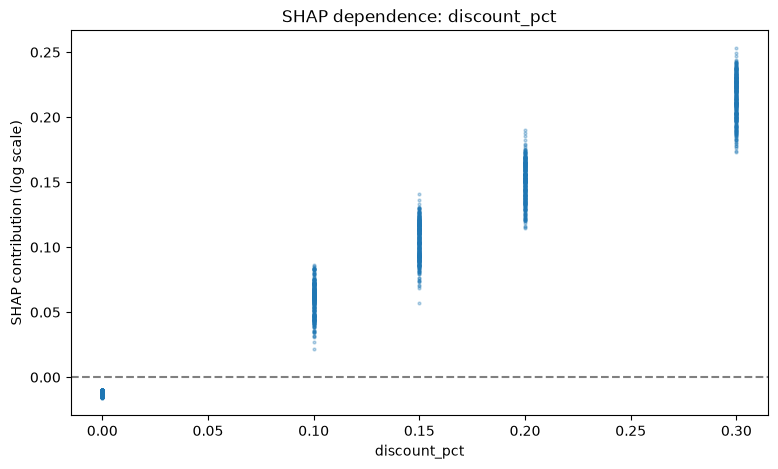

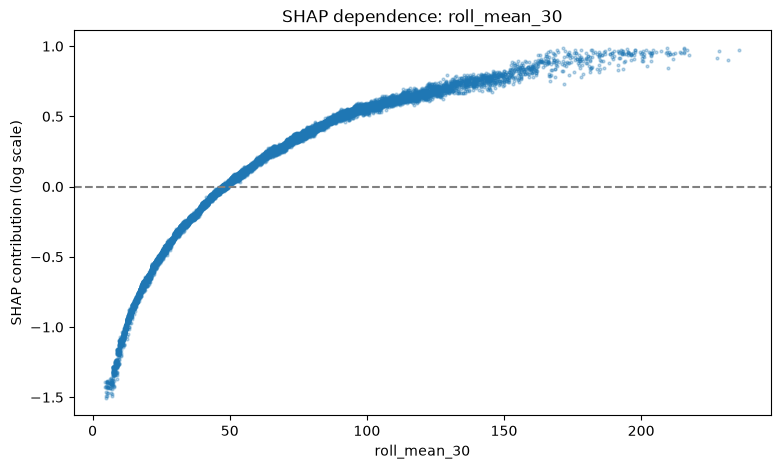

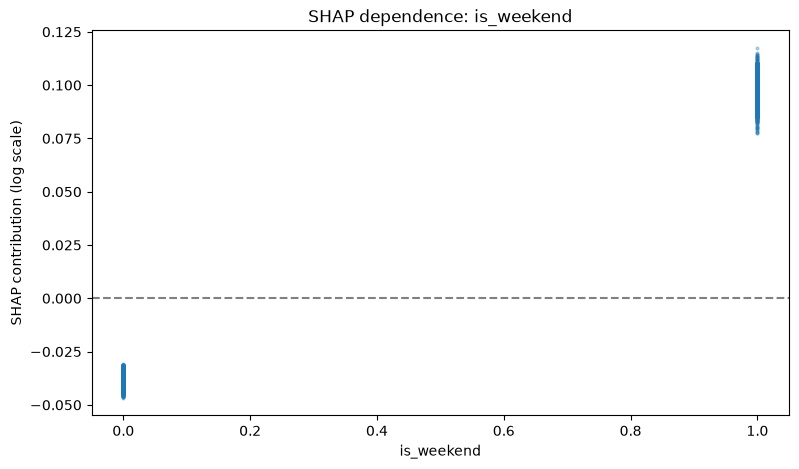

Multiplier on expected units from promotion flag + discount (the 0.000 row is the no-promotion reference):
discount
0.000   0.957
0.100   1.554
0.150   1.636
0.200   1.740
0.300   1.905


In [8]:
for f in ["discount_pct", "roll_mean_30", "is_weekend"]:
    plt.scatter(X[f], sv[:, feature_cols.index(f)], s=4, alpha=0.3)
    plt.axhline(0, color="grey", linestyle="--")
    plt.xlabel(f)
    plt.ylabel("SHAP contribution" + (" (log scale)" if LOG_SCALE else " (units)"))
    plt.title(f"SHAP dependence: {f}")
    savefig(f"shap_dependence_{f}")
    plt.show()

# Average effect of a promotion in plain terms
promo_effect = pd.DataFrame({"discount": sample["discount_pct"], "shap": sv[:, feature_cols.index("discount_pct")],
                             "promo_flag_shap": sv[:, feature_cols.index("promo_flag")]})
promo_effect["promo_total"] = promo_effect["shap"] + promo_effect["promo_flag_shap"]
by_depth = promo_effect.groupby("discount")["promo_total"].mean()
if LOG_SCALE:
    by_depth = np.exp(by_depth)
    print("Multiplier on expected units from promotion flag + discount (the 0.000 row is the no-promotion reference):")
else:
    print("Average contribution (units) from promotion flag + discount:")
print(by_depth.round(3).to_string())

## 6. Explaining individual forecasts
Two forecasts for the same high-revenue series: one on a **promotion day** and one on a **comparable day without a promotion** (same weekday). Seeing the contributions side by side shows what a planner would see.

In [9]:
seg = pd.read_csv("../data/abc_xyz_segments.csv").set_index("series_id")
ax_series = seg[seg["segment"] == "AX"].sort_values("net_sales", ascending=False).index
sid = next((s for s in ax_series if ((test["series_id"] == s) & (test["promo_flag"] == 1)).any()), None)
assert sid is not None, "No AX series with a promotion in the test period"

g = test[test["series_id"] == sid].sort_values("date")
promo_row = g[g["promo_flag"] == 1].iloc[len(g[g["promo_flag"] == 1]) // 2]
normal_row = g[(g["promo_flag"] == 0) & (g["weekday"] == promo_row["weekday"])].iloc[0]

def explain_row(row, label):
    xr = row[feature_cols].to_frame().T.astype(float)
    sv_r = booster.predict(xr, pred_contrib=True)[0][:-1]
    pred = booster.predict(xr)[0]
    df_r = pd.DataFrame({"value": xr.iloc[0].values, "contribution": sv_r}, index=feature_cols)
    if LOG_SCALE:
        df_r["multiplier"] = np.exp(df_r["contribution"])
    top = df_r.reindex(df_r["contribution"].abs().sort_values(ascending=False).index).head(6)
    print(f"\n{label}: {sid}, {row['date'].date()}, actual {row[target]:.0f}, forecast {pred:.1f}")
    print(top.round(3).to_string())

explain_row(promo_row, "PROMOTION DAY")
explain_row(normal_row, "NO-PROMOTION DAY")


PROMOTION DAY: STORE0008_SKU0027, 2023-09-28, actual 256, forecast 176.3
               value  contribution  multiplier
roll_mean_30 123.267         0.703       2.020
promo_flag     1.000         0.416       1.515
roll_mean_7  120.857         0.108       1.114
discount_pct   0.150         0.092       1.096
is_weekend     0.000        -0.038       0.962
promo_last7    2.000        -0.033       0.968

NO-PROMOTION DAY: STORE0008_SKU0027, 2023-07-13, actual 132, forecast 96.9
               value  contribution  multiplier
roll_mean_30 114.167         0.645       1.906
roll_mean_7  106.429         0.115       1.122
is_weekend     0.000        -0.038       0.963
promo_flag     0.000        -0.038       0.963
promo_last7    1.000        -0.035       0.966
abc_code       0.000         0.028       1.028


# Part B: Ethical bias check (Traditional Trade)

## 7. Forecast bias by channel
**Bias** = (total forecast - total actual) / total actual. A negative value means the model under-forecasts that channel, so any allocation driven by the forecast would under-supply it. We report it on:
- **Non-stock-out days** (primary): sales equal real demand there.
- **All days:** stock-out days have suppressed sales, which inflates apparent over-forecasting in channels with more stock-outs.

The forecasts are the Phase 5 test-period predictions (Jul-Dec 2023).

In [10]:
pred = pd.read_csv("../data/test_predictions.csv", parse_dates=["date"])        # series_id, date, y, pred
clean = pd.read_csv("../data/fmcg_clean.csv",
                    usecols=["store_id", "sku_id", "date", "channel", "category", "stock_out_flag"],
                    parse_dates=["date"])
clean["series_id"] = clean["store_id"] + "_" + clean["sku_id"]
chan = clean.drop_duplicates("series_id").set_index("series_id")[["channel", "category"]]

df = (pred.merge(clean[["series_id", "date", "stock_out_flag"]], on=["series_id", "date"], how="left")
          .join(chan, on="series_id"))
group_map = {"Hypermarket": "Modern Trade", "Supermarket": "Modern Trade",
             "Convenience": "Traditional Trade (proxy)", "E-commerce": "E-commerce"}
df["trade_group"] = df["channel"].map(group_map)
print("Test rows:", f"{len(df):,}", "| series:", df["series_id"].nunique())

def bias_table(d, by):
    t = d.groupby(by).agg(series=("series_id", "nunique"), rows=("y", "size"),
                          actual=("y", "sum"), forecast=("pred", "sum"))
    t["abs_err"] = d.assign(e=(d["y"] - d["pred"]).abs()).groupby(by)["e"].sum()
    t["bias_%"] = (t["forecast"] / t["actual"] - 1) * 100
    t["WAPE"] = t["abs_err"] / t["actual"]
    t["under_forecast_days_%"] = d.assign(u=(d["pred"] < d["y"]) * 1).groupby(by)["u"].mean() * 100
    return t[["series", "rows", "bias_%", "WAPE", "under_forecast_days_%"]]

normal = df[df["stock_out_flag"] == 0]
print("\nNon-stock-out days, by channel:")
tbl_normal = bias_table(normal, "channel")
print(tbl_normal.round(3).to_string())
print("\nNon-stock-out days, by trade group:")
print(bias_table(normal, "trade_group").round(3).to_string())
print("\nAll days, by channel:")
print(bias_table(df, "channel").round(3).to_string())
tbl_normal.to_csv("../reports/bias_by_channel.csv")

Test rows: 184,736 | series: 1004

Non-stock-out days, by channel:
             series   rows  bias_%  WAPE  under_forecast_days_%
channel                                                        
Convenience      44   7858  -2.046 0.243                 51.413
E-commerce      240  42826  -2.272 0.244                 52.484
Hypermarket     480  85630  -2.579 0.244                 52.980
Supermarket     240  42925  -2.166 0.245                 52.424

Non-stock-out days, by trade group:
                           series    rows  bias_%  WAPE  under_forecast_days_%
trade_group                                                                   
E-commerce                    240   42826  -2.272 0.244                 52.484
Modern Trade                  720  128555  -2.471 0.244                 52.795
Traditional Trade (proxy)      44    7858  -2.046 0.243                 51.413

All days, by channel:
             series   rows  bias_%  WAPE  under_forecast_days_%
channel                       

### 7.1 Is the difference between channels statistically real?
Bias in the totals could come from a few series. We therefore:
1. compute the **bias of each series** (forecast / actual - 1) and compare channels (Kruskal-Wallis);
2. **bootstrap** 95% confidence intervals by resampling series, for each channel and for the **difference between Traditional Trade (proxy) and Modern Trade**.

A confidence interval that includes 0 means we cannot detect bias. The interval width also shows how large a bias this data could rule out, which matters because Convenience has few series.

In [11]:
per_series = normal.groupby("series_id").agg(y=("y", "sum"), pred=("pred", "sum")).join(chan)
per_series["bias"] = per_series["pred"] / per_series["y"] - 1

groups_ = [g["bias"].values for _, g in per_series.groupby("channel")]
H, p = st.kruskal(*groups_)
print(f"Kruskal-Wallis on per-series bias across channels: H = {H:.2f}, p = {p:.3f}")

rng = np.random.default_rng(SEED)
def boot_bias(sub, B=4000):
    y, f = sub["y"].values, sub["pred"].values
    idx = rng.integers(0, len(sub), (B, len(sub)))
    return f[idx].sum(axis=1) / y[idx].sum(axis=1) - 1

rows = []
boots = {}
for ch, sub in per_series.groupby("channel"):
    b = boot_bias(sub)
    boots[ch] = b
    rows.append({"channel": ch, "series": len(sub), "bias_%": (sub["pred"].sum() / sub["y"].sum() - 1) * 100,
                 "ci95_low_%": np.percentile(b, 2.5) * 100, "ci95_high_%": np.percentile(b, 97.5) * 100})
ci = pd.DataFrame(rows).set_index("channel")
print("\nBootstrap 95% confidence intervals for bias (resampling series):")
print(ci.round(2).to_string())

modern = per_series[per_series["channel"].isin(["Hypermarket", "Supermarket"])]
trad = per_series[per_series["channel"] == "Convenience"]
diff = boot_bias(trad) - boot_bias(modern)
print(f"\nTraditional Trade (proxy) minus Modern Trade bias: {np.median(diff)*100:.2f} percentage points "
      f"(95% CI {np.percentile(diff, 2.5)*100:.2f} to {np.percentile(diff, 97.5)*100:.2f})")
print("Interval contains 0 (no detectable gap)?", np.percentile(diff, 2.5) <= 0 <= np.percentile(diff, 97.5))
ci.to_csv("../reports/bias_ci_by_channel.csv")

Kruskal-Wallis on per-series bias across channels: H = 6.60, p = 0.086

Bootstrap 95% confidence intervals for bias (resampling series):
             series  bias_%  ci95_low_%  ci95_high_%
channel                                             
Convenience      44  -2.050      -2.780       -1.250
E-commerce      240  -2.270      -2.500       -2.050
Hypermarket     480  -2.580      -2.750       -2.410
Supermarket     240  -2.170      -2.420       -1.910

Traditional Trade (proxy) minus Modern Trade bias: 0.40 percentage points (95% CI -0.31 to 1.22)
Interval contains 0 (no detectable gap)? True


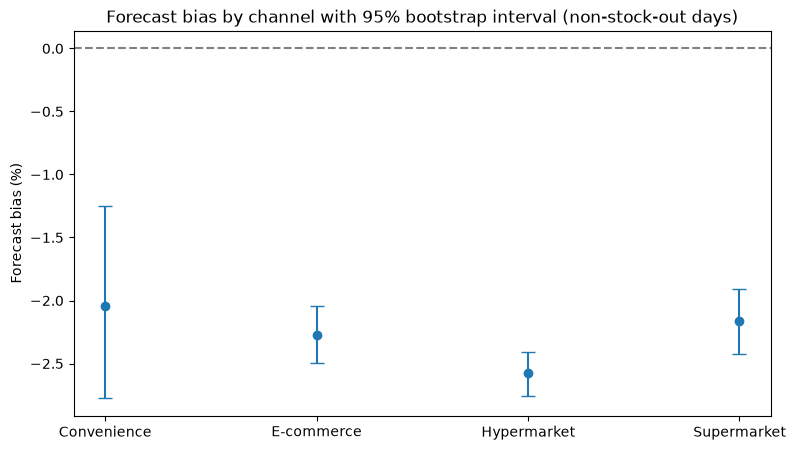

In [12]:
order = ci.index.tolist()
plt.errorbar(range(len(order)), ci["bias_%"],
             yerr=[ci["bias_%"] - ci["ci95_low_%"], ci["ci95_high_%"] - ci["bias_%"]], fmt="o", capsize=5)
plt.axhline(0, color="grey", linestyle="--")
plt.xticks(range(len(order)), order)
plt.ylabel("Forecast bias (%)")
plt.title("Forecast bias by channel with 95% bootstrap interval (non-stock-out days)")
savefig("bias_by_channel")
plt.show()

## 8. Bias by channel and category (essential goods)
The brief stresses that stock-outs in Traditional Trade affect access to **food and essential goods**. We check whether any channel-category cell is systematically under-forecast. We flag cells beyond **+/-3%** (a monitoring threshold chosen for illustration).

Forecast bias (%) by channel and category (non-stock-out days):
category     Beverages  Dairy  Home Care  Personal Care  Snacks
channel                                                        
Convenience     -0.640 -2.320     -2.150         -2.740  -2.990
E-commerce      -1.860 -2.490     -2.140         -2.310  -2.650
Hypermarket     -2.330 -2.750     -2.560         -2.550  -2.760
Supermarket     -1.740 -2.020     -2.050         -2.320  -2.660

Cells beyond +/-3%: none


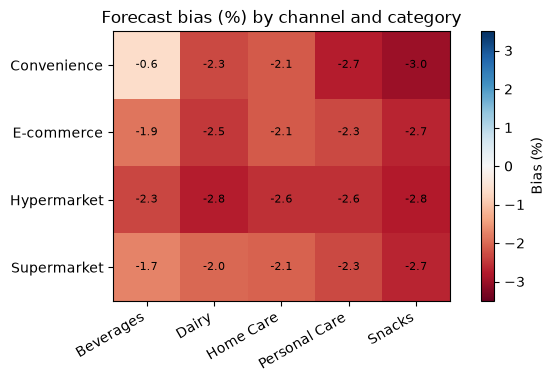

In [13]:
cc = (normal.groupby(["channel", "category"]).agg(y=("y", "sum"), f=("pred", "sum")))
cc["bias_%"] = (cc["f"] / cc["y"] - 1) * 100
pivot = cc["bias_%"].unstack("category")
print("Forecast bias (%) by channel and category (non-stock-out days):")
print(pivot.round(2).to_string())
flagged = cc[cc["bias_%"].abs() > 3]
print("\nCells beyond +/-3%:", "none" if flagged.empty else "")
if not flagged.empty:
    print(flagged.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
lim = max(3.5, np.nanmax(np.abs(pivot.values)))
im = ax.imshow(pivot.values, cmap="RdBu", vmin=-lim, vmax=lim)
ax.set_xticks(range(pivot.shape[1]), pivot.columns, rotation=30, ha="right")
ax.set_yticks(range(pivot.shape[0]), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Bias (%)")
ax.set_title("Forecast bias (%) by channel and category")
savefig("bias_channel_category")
plt.show()

## 9. What would an allocation based on this forecast do?
The brief worries about stock being **under-allocated** to Traditional Trade. We simulate a simple rule over the test period, week by week:
- Total supply each week is **95% of total demand** (so there is not enough for everyone; allocation choices matter).
- **Rule A (forecast-based):** share the supply across channels in proportion to each channel's forecast.
- **Rule B (past-sales-based):** share it in proportion to each channel's sales share over the previous 4 weeks.
- **Fill rate** = units that can be sold / units demanded, for each channel. Stock allocated beyond a channel's demand is wasted in this simplified model.
- **Fairness criterion:** the gap between the highest and lowest channel fill rate should be small (we use under 1 percentage point as the illustrative target).

We then **stress-test**: what happens if the Traditional Trade forecast were biased low by 2%, 5% or 10%? This shows how much bias would matter and sets a sensible monitoring threshold.

In [14]:
d = df.assign(week=df["date"].dt.to_period("W"))
Y = d.groupby(["week", "channel"])["y"].sum().unstack()
P = d.groupby(["week", "channel"])["pred"].sum().unstack()
Y, P = Y.iloc[1:-1], P.iloc[1:-1]                       # drop the partial first and last weeks

SUPPLY = 0.95
supply = SUPPLY * Y.sum(axis=1)

trail = Y.rolling(4).sum().shift(1)
trail_share = trail.div(trail.sum(axis=1), axis=0)
weeks = trail_share.dropna().index                       # weeks that have 4 prior weeks of history
Yw, Pw = Y.loc[weeks], P.loc[weeks]

alloc_fc = Pw.div(Pw.sum(axis=1), axis=0).mul(supply.loc[weeks], axis=0)
alloc_tr = trail_share.loc[weeks].mul(supply.loc[weeks], axis=0)

fill = pd.DataFrame({"Rule A: forecast-based": np.minimum(alloc_fc, Yw).sum() / Yw.sum() * 100,
                     "Rule B: past-sales-based": np.minimum(alloc_tr, Yw).sum() / Yw.sum() * 100})
print(f"Weeks simulated: {len(weeks)} | supply = {SUPPLY*100:.0f}% of demand")
print("\nFill rate (%) by channel:")
print(fill.round(2).to_string())
print("\nFairness gap (highest minus lowest fill rate, percentage points):")
print((fill.max() - fill.min()).round(2).to_string())
fill.to_csv("../reports/allocation_fill_rates.csv")

Weeks simulated: 21 | supply = 95% of demand

Fill rate (%) by channel:
             Rule A: forecast-based  Rule B: past-sales-based
channel                                                      
Convenience                  95.070                    94.760
E-commerce                   95.160                    95.020
Hypermarket                  94.890                    94.990
Supermarket                  95.090                    95.030

Fairness gap (highest minus lowest fill rate, percentage points):
Rule A: forecast-based     0.270
Rule B: past-sales-based   0.260


In [15]:
rows = []
for delta in [0, 0.02, 0.05, 0.10]:
    P2 = Pw.copy()
    P2["Convenience"] = P2["Convenience"] * (1 - delta)          # simulate a model that under-forecasts Traditional Trade
    alloc = P2.div(P2.sum(axis=1), axis=0).mul(supply.loc[weeks], axis=0)
    fr = np.minimum(alloc, Yw).sum() / Yw.sum() * 100
    rows.append({"Convenience under-forecast": f"{delta*100:.0f}%",
                 "Convenience fill %": fr["Convenience"],
                 "Other channels fill %": fr.drop("Convenience").mean(),
                 "gap (pp)": fr.drop("Convenience").mean() - fr["Convenience"]})
stress = pd.DataFrame(rows).set_index("Convenience under-forecast")
print("Stress test: effect of a biased-low Traditional Trade forecast on its fill rate")
print(stress.round(2).to_string())
stress.to_csv("../reports/allocation_stress_test.csv")

Stress test: effect of a biased-low Traditional Trade forecast on its fill rate
                            Convenience fill %  Other channels fill %  gap (pp)
Convenience under-forecast                                                     
0%                                      95.070                 95.050    -0.020
2%                                      93.260                 95.100     1.840
5%                                      90.480                 95.170     4.700
10%                                     85.830                 95.300     9.470


## 10. Do Traditional Trade stores already suffer more stock-outs?
Bias in the forecast is one risk; unequal actual stock-outs are another. We compare stock-out rates by channel over the whole dataset (chi-square test of independence).

In [16]:
so_all = pd.read_csv("../data/fmcg_clean.csv", usecols=["channel", "stock_out_flag"])
so_rate = so_all.groupby("channel")["stock_out_flag"].agg(rows="size", rate_pct=lambda s: s.mean() * 100)
print(so_rate.round(3).to_string())
chi2, p, _, _ = st.chi2_contingency(pd.crosstab(so_all["channel"], so_all["stock_out_flag"]))
print(f"\nChi-square test of channel vs stock-out: chi2 = {chi2:.2f}, p = {p:.3f}")

               rows  rate_pct
channel                      
Convenience   48800     3.037
E-commerce   262800     3.009
Hypermarket  525600     3.026
Supermarket  262800     2.975

Chi-square test of channel vs stock-out: chi2 = 1.72, p = 0.633


## 11. A governance checklist for fair allocation
A model can be accurate overall and still disadvantage a small group, so fairness needs ongoing monitoring, not a one-off test. Based on the checks above, a planner could adopt:

1. **Track forecast bias by channel every week** (section 7), and investigate any channel outside a tolerance (for example +/-3%).
2. **Track fill-rate parity** (section 9): the gap between the best- and worst-served channel should stay small (for example under 1 percentage point) when supply is constrained.
3. **Review small channels by hand.** Small channels have few series, so statistical tests have low power; automatic checks can miss a real problem there.
4. **Protect essential goods.** For food and essential categories in Traditional Trade, set a minimum allocation floor so a forecast error cannot strip a community outlet of basic stock.
5. **Compare forecast-based allocation with a simple past-sales rule** (section 9) so that a more complex method is only adopted if it is not worse for any channel.
6. **Re-run this audit** after any model retraining or major change in the channel mix.

**Limits of this analysis:** Convenience is only a proxy for Traditional Trade; this is European data with 45 Convenience series; the allocation simulation is deliberately simple (no redistribution of unused stock, no transport constraints); fairness is defined here through forecast bias and fill-rate parity, and other definitions are possible.

## 12. Summary of findings

**Explainability**

- **Feature groups (section 4):** Recent demand history carries 68.0% of the model's SHAP importance, calendar effects 10.6%, the active promotion (flag and discount depth) 9.6%, series identity 8.5%, price and weather 2.4% and stock-out history 0.9%. The model therefore relies mainly on recent demand history; a single feature, `roll_mean_30`, accounts for 49.7% of SHAP importance. SHAP and LightGBM gain agree on the top three (`roll_mean_30`, `roll_mean_7`, `promo_flag`) but gain overstates the 30-day level (75.2% vs 49.7%) and understates `is_weekend` (1.4% vs 6.4%) and `promo_last7` (1.0% vs 4.6%), so gain alone would understate the calendar and promotion-history effects. The additivity check passed (base value plus SHAP contributions reproduces the model output, maximum difference 0.000000). SHAP was computed on a sample of 20,000 of the 184,736 test rows.

- **Promotion and weekend effects (section 5):** Contributions are on the log scale because the model uses a Poisson objective, so `exp()` gives multipliers. Relative to the no-promotion reference (0.957), a 10% discount multiplies expected units by about 1.62 (1.554 / 0.957), 15% by 1.71, 20% by 1.82 and 30% by 1.99. This is broadly consistent with the arc-elasticity results in notebook 06. The weekend and discount effects are shown in the beeswarm and dependence plots in `reports/figures`.

- **Individual forecasts (section 6):** For series STORE0008_SKU0027, the 30-day demand level is the largest contributor on both days (x2.02 on the promotion day, x1.91 on the non-promotion day). On the promotion day (2023-09-28) the promotion flag adds x1.52 and the 15% discount x1.10, giving a forecast of 176 against an actual of 256. On the non-promotion day (2023-07-13) the forecast was 97 against an actual of 132. Both forecasts were 27-31% below the actual, consistent with the day-to-day noise that none of the models captures (see notebook 07).

**Ethics (Traditional Trade, with Convenience stores as the proxy)**

- **Forecast bias by channel (section 7):** On non-stock-out days all channels are slightly under-forecast: Convenience -2.05%, E-commerce -2.27%, Supermarket -2.17% and Hypermarket -2.58%, with 51-53% of days under-forecast and WAPE of 0.243-0.245 in every channel. Traditional Trade (proxy) is under-forecast slightly less than Modern Trade (-2.05% vs -2.47%); the difference of 0.40 percentage points has a 95% bootstrap interval of -0.31 to 1.22, which contains 0, so there is no detectable gap. The Kruskal-Wallis test across the four channels gives H = 6.60, p = 0.086, not significant at the 5% level. Over all days (including stock-outs) bias is close to zero in every channel (-0.08% to +0.26%); the roughly 2% under-forecast on normal days is likely because the model is trained on all days and stock-out days have much lower sales. Convenience has only 44 series, so its interval (-2.78% to -1.25%) is the widest.

- **Channel and category (section 8):** No channel-category cell is beyond +/-3%. The largest is Convenience Snacks at -2.99%, just inside the threshold, and the smallest is Convenience Beverages at -0.64%.

- **Allocation simulation (section 9):** Over 21 simulated weeks with supply at 95% of demand, forecast-based allocation (Rule A) gives fill rates of 94.89-95.16% across channels (fairness gap 0.27 percentage points; Convenience 95.07%). Past-sales allocation (Rule B) gives 94.76-95.03% (gap 0.26 points; Convenience 94.76%). Forecast-based allocation therefore does not disadvantage Traditional Trade. The stress test shows how sensitive this is: if the Convenience forecast were biased low by an extra 2%, its fill rate would fall to 93.26% and the gap would reach 1.84 points, above the 1 percentage point target; at 5% the gap is 4.70 points and at 10% it is 9.47. Linear interpolation puts the 1-point limit at an extra under-forecast of roughly 1%.

- **Stock-outs by channel (section 10):** Stock-out rates are essentially identical across channels (Convenience 3.04%, E-commerce 3.01%, Hypermarket 3.03%, Supermarket 2.98%; chi-square = 1.72, p = 0.633), so Traditional Trade does not already suffer more stock-outs. This is consistent with the finding in notebook 07 that stock-outs in this dataset look largely random.

- **Conclusion:** There is no evidence that the forecast under-serves Traditional Trade relative to Modern Trade or E-commerce. Because the allocation outcome is sensitive to even a small extra bias, we recommend monitoring Traditional Trade bias every cycle and reviewing the model if it becomes about 1 percentage point worse than Modern Trade bias (see the governance checklist in section 11).

**Limitations**

- Convenience stores are only a proxy for Traditional Trade (44 series), and the data appear simulated, so the findings may not transfer to real informal retail.
- An interval that contains 0 shows no detectable gap, not proof of no gap; the data cannot rule out a difference of up to about 1.2 points.
- The allocation simulation is simplified (supply fixed at 95% of demand, channel-level rather than store-level fill rates, 21 weeks of a single test period).
- SHAP values show what the model uses, not causal effects, and the figures come from a sample of 20,000 test rows.